# Market regimes

Risk models behave differently in calm and stressed markets. This note labels each day as calm, normal or stress, and measures how the VaR methods of [`04_backtest`](04_backtest.ipynb) and the volatility models of [`02_volatility`](02_volatility.ipynb) perform in each regime (gold tables `fact_regime`, `fact_regime_profile`, `fact_regime_transition`, `fact_backtest_regime` and `fact_forecast_regime`, produced by [`pipeline/regimes.py`](../pipeline/regimes.py)).

**Features**, at each close: the 22-day volatility of the three equity indices (in logs), their 22-day return, the average pairwise correlation of their daily returns over 63 days, and the VIX (in logs).

**Models.** A three-state Gaussian hidden Markov model (HMM; Hamilton, 1989; Rabiner, 1989), whose transition matrix makes regimes persist, and a Gaussian mixture (GMM) on the same features, which treats every day independently. States are ordered by average volatility and named calm, normal and stress.

**Two fits.** The *full-history* HMM is fitted on every day from 2008 and labels each day with smoothed probabilities, which use later data: it describes the past and is used for analysis only. The *walk-forward* HMM is refitted every January from 2012 on past data, standardised with past statistics only, and filtered forward: its regime on a day uses nothing after that day's close.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
GOLD = ROOT / "data" / "gold"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
REGIME_NAMES = {0: "calm", 1: "normal", 2: "stress"}
REGIME_SHADES = {1: "#e6e5e1", 2: "#f6cfcb"}
METHOD_COLORS = {"hs": "#a9a8a3", "param_champion": "#2a78d6", "fhs": "#eb6834"}
METHOD_NAMES = {
    "hs": "Historical simulation",
    "param_ewma": "Parametric (EWMA)",
    "param_garch": "Parametric (GARCH)",
    "param_champion": "Parametric (GJR)",
    "fhs": "Filtered historical simulation",
}
plt.rcParams.update(
    {
        "figure.figsize": (9, 3.6),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
        "font.size": 9,
    }
)

regimes = pd.read_parquet(GOLD / "fact_regime.parquet").assign(date=lambda d: pd.to_datetime(d["date"]))
profile = pd.read_parquet(GOLD / "fact_regime_profile.parquet")
transitions = pd.read_parquet(GOLD / "fact_regime_transition.parquet")
by_regime = pd.read_parquet(GOLD / "fact_backtest_regime.parquet")
losses = pd.read_parquet(GOLD / "fact_forecast_regime.parquet")
market = pd.read_parquet(GOLD / "fact_market.parquet").assign(date=lambda d: pd.to_datetime(d["date"]))


def labels(method: str, fit: str) -> pd.Series:
    rows = regimes[(regimes["method"] == method) & (regimes["fit"] == fit)]
    return rows.set_index("date")["regime_id"]


full, live, mixture = (
    labels("hmm", "full_history"),
    labels("hmm", "walk_forward"),
    labels("gmm", "full_history"),
)
print(
    f"Regimes from {full.index.min():%d %b %Y} to {full.index.max():%d %b %Y} ({len(full)} days); walk-forward from {live.index.min():%d %b %Y}"
)

Regimes from 28 Feb 2008 to 21 Oct 2026 (4817 days); walk-forward from 02 Jan 2012


## 1. Choosing the features and the number of regimes

The guide also lists the yield curve slope. With it, the HMM's middle state became the steep-curve years of the early 2010s (a 2-point slope, spells of about 645 days): a rates era rather than a market condition, and the HMM and GMM agreed on only 13% of days. The slope moves too slowly to describe a regime that lasts weeks, so it was dropped. BIC (Schwarz, 1978) keeps falling from two to five states, as it usually does on long financial series, so it does not select the number of regimes; three were kept because each has a clear economic meaning.

In [2]:
def profile_table(method: str, fit: str) -> pd.DataFrame:
    rows = (
        profile[(profile["method"] == method) & (profile["fit"] == fit)].set_index("regime_id").sort_index()
    )
    table = rows[
        ["share_of_days", "mean_duration_days", "volatility", "return_22d", "correlation_63d", "vix"]
    ]
    return table.rename(index=REGIME_NAMES)


print("Full-history HMM")
display(profile_table("hmm", "full_history").round(3))
print("Walk-forward HMM (from 2012)")
display(profile_table("hmm", "walk_forward").round(3))
print("Full-history Gaussian mixture")
profile_table("gmm", "full_history").round(3)

Full-history HMM


,share_of_days,mean_duration_days,volatility,return_22d,correlation_63d,vix
regime_id,,,,,,
calm,0.387,68.963,0.125,0.012,0.628,15.224
normal,0.361,66.885,0.170,0.024,0.787,19.828
stress,0.252,40.533,0.281,-0.030,0.684,26.706


Walk-forward HMM (from 2012)


,share_of_days,mean_duration_days,volatility,return_22d,correlation_63d,vix
regime_id,,,,,,
calm,0.576,52.405,0.131,0.012,0.656,14.986
normal,0.240,23.564,0.163,0.008,0.757,18.310
stress,0.184,23.467,0.238,-0.003,0.661,25.426


Full-history Gaussian mixture


,share_of_days,mean_duration_days,volatility,return_22d,correlation_63d,vix
regime_id,,,,,,
calm,0.484,17.281,0.119,0.017,0.661,14.907
normal,0.364,11.464,0.208,0.019,0.767,21.029
stress,0.152,10.429,0.310,-0.062,0.658,32.381


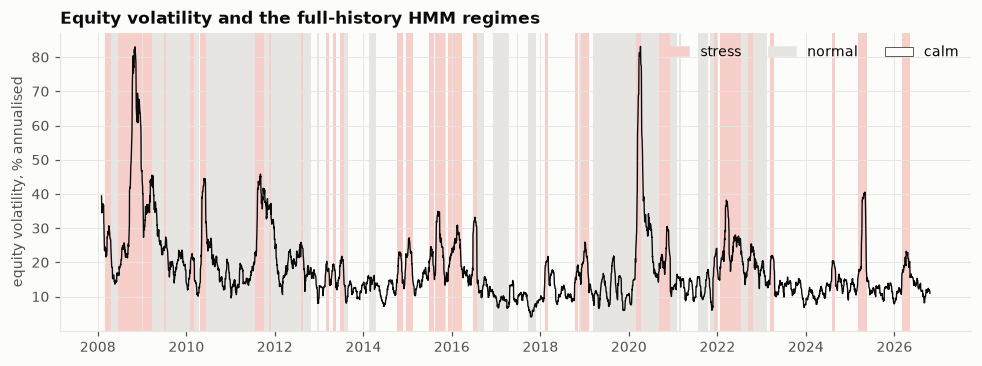

In [3]:
equity_vol = (
    market[market["instrument_id"].isin(["CAC40", "SX5E", "SPX"])]
    .pivot(index="date", columns="instrument_id", values="vol_22d")
    .mean(axis=1)
)
fig, ax = plt.subplots(figsize=(9, 3.4))
spells = full.groupby((full != full.shift()).cumsum())
for _, spell in spells:
    regime = spell.iloc[0]
    if regime in REGIME_SHADES:
        ax.axvspan(spell.index[0], spell.index[-1], color=REGIME_SHADES[regime], linewidth=0, zorder=0)
ax.plot(equity_vol.index, equity_vol * 100, color=INK, linewidth=0.9)
ax.set_ylabel("equity volatility, % annualised")
ax.set_title("Equity volatility and the full-history HMM regimes")
ax.legend(
    handles=[
        Patch(color=REGIME_SHADES[2], label="stress"),
        Patch(color=REGIME_SHADES[1], label="normal"),
        Patch(facecolor=SURFACE, edgecolor=INK2, linewidth=0.6, label="calm"),
    ],
    loc="upper right",
    ncol=3,
)
plt.tight_layout()
plt.show()

The full-history HMM finds a calm regime on 39% of days (equity volatility 12.5%, VIX 15.2), a normal regime on 36% (volatility 17.0%, the highest equity correlation, 0.79) and a stress regime on 25% (volatility 28.1%, VIX 26.7, a 22-day return of −3.0%). Regimes persist: an average calm spell lasts 69 days, a stress spell 41. The Gaussian mixture finds similar clouds but switches every 10 to 17 days on average, because it ignores what happened the day before; the HMM's transition matrix is what makes the labels usable. The walk-forward HMM, which only knows the past, calls fewer days stressed (18%) and switches more often (stress spells of 23 days against 41).

## 2. Do the regimes match known episodes, and do they persist?

In [4]:
years = [2008, 2011, 2015, 2018, 2020, 2022, 2025, full.index.max().year]
composition = pd.DataFrame(
    {
        "stress share, full history": {year: (full[str(year)] == 2).mean() for year in years},
        "stress share, walk-forward": {
            year: (live[str(year)] == 2).mean() if year >= live.index.min().year else np.nan for year in years
        },
        "calm share, full history": {year: (full[str(year)] == 0).mean() for year in years},
    }
).round(2)
onset = {
    name: series["2020-02-01":"2020-04-30"][series["2020-02-01":"2020-04-30"] == 2].index.min()
    for name, series in [("full history", full), ("walk-forward", live)]
}
common = full.index.intersection(live.index)
print(
    f"First stress day of 2020: full history {onset['full history']:%d %b %Y}, walk-forward {onset['walk-forward']:%d %b %Y}"
)
print(
    f"Agreement since {live.index.min().year}: same regime on {(full[common] == live[common]).mean():.1%} of days, same stress/not-stress call on {((full[common] == 2) == (live[common] == 2)).mean():.1%}"
)
print(
    f"HMM and Gaussian mixture (full history) agree on {(full == mixture.reindex(full.index)).mean():.1%} of days"
)
composition

First stress day of 2020: full history 27 Feb 2020, walk-forward 27 Feb 2020
Agreement since 2012: same regime on 66.1% of days, same stress/not-stress call on 79.9%
HMM and Gaussian mixture (full history) agree on 72.1% of days


,"stress share, full history","stress share, walk-forward","calm share, full history"
2008,0.83,NaN,0.00
2011,0.26,NaN,0.00
2015,0.54,0.02,0.42
2018,0.22,0.21,0.71
2020,0.38,0.76,0.00
2022,0.61,0.80,0.04
2025,0.21,0.19,0.79
2026,0.22,0.00,0.78


In [5]:
matrix = transitions[(transitions["method"] == "hmm") & (transitions["fit"] == "full_history")].pivot(
    index="regime_from", columns="regime_to", values="probability"
)
matrix = matrix.rename(index=REGIME_NAMES, columns=REGIME_NAMES)
print("Day-to-day transition frequencies, full-history HMM (rows: today, columns: tomorrow)")
matrix.round(3)

Day-to-day transition frequencies, full-history HMM (rows: today, columns: tomorrow)


regime_to,calm,normal,stress
regime_from,,,
calm,0.986,0.005,0.009
normal,0.008,0.985,0.007
stress,0.011,0.014,0.975


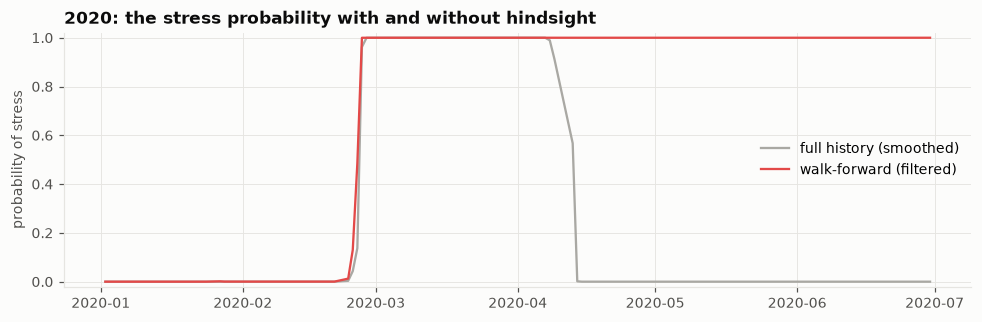

In [6]:
window = slice("2020-01-01", "2020-06-30")
fig, ax = plt.subplots(figsize=(9, 3.0))
for name, fit, color in [
    ("full history (smoothed)", "full_history", "#a9a8a3"),
    ("walk-forward (filtered)", "walk_forward", "#e34948"),
]:
    rows = regimes[(regimes["method"] == "hmm") & (regimes["fit"] == fit)].set_index("date").loc[window]
    ax.plot(rows.index, rows["p_stress"], color=color, label=name)
ax.set_ylim(-0.02, 1.02)
ax.set_ylabel("probability of stress")
ax.set_title("2020: the stress probability with and without hindsight")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

The known episodes are in stress: 83% of 2008, 61% of 2022 in the full-history fit (80% walk-forward), and the 2020 crash, which both fits enter on 27 February. Regimes are sticky: the full-history HMM stays in its regime from one day to the next with a frequency of 0.975 to 0.986. Since 2012 the two fits give the same regime on 66.1% of days and the same stress call on 79.9%. The largest gap is 2015: 54% stress with hindsight, 2% for the walk-forward fit, which was trained on 2008-2014 and, having seen 2008, judged 2015's turbulence moderate. A regime label is relative to the history the model has seen, so any use of regimes must say which fit it uses. In 2020 the filtered probability enters stress on the same day as the smoothed one, but stays there through June, where hindsight moves to the normal regime in mid-April.

## 3. VaR exceptions by regime

Each exception of the 1-day VaR 99% is attributed to the regime at the close when the VaR was computed, so the walk-forward attribution uses only information available at that time. A correct VaR is exceeded on 1% of days in every regime; Kupiec's test (1995) checks each cell.

In [7]:
def exceptions_table(fit: str) -> pd.DataFrame:
    rows = by_regime[by_regime["fit"] == fit].assign(regime=lambda d: d["regime_id"].map(REGIME_NAMES))
    cells = rows.assign(
        cell=rows["n_exceptions"].astype(str)
        + " / "
        + rows["expected_exceptions"].round(1).astype(str)
        + " (p "
        + rows["kupiec_p"].round(3).astype(str)
        + ")"
    )
    table = cells.pivot(index="method_id", columns="regime", values="cell")[["calm", "normal", "stress"]]
    return table.rename(index=METHOD_NAMES)


days = by_regime[by_regime["method_id"] == "fhs"].set_index(["fit", "regime_id"])["n_days"]
print(
    "Exceptions / expected (Kupiec p), full-history regimes; days per regime:",
    {REGIME_NAMES[r]: int(days[("full_history", r)]) for r in range(3)},
)
display(exceptions_table("full_history"))
print(
    "Same, walk-forward regimes; days per regime:",
    {REGIME_NAMES[r]: int(days[("walk_forward", r)]) for r in range(3)},
)
exceptions_table("walk_forward")

Exceptions / expected (Kupiec p), full-history regimes; days per regime: {'calm': 1850, 'normal': 1122, 'stress': 851}


regime,calm,normal,stress
method_id,,,
Filtered historical simulation,20 / 18.5 (p 0.729),12 / 11.2 (p 0.817),6 / 8.5 (p 0.361)
Historical simulation,21 / 18.5 (p 0.567),13 / 11.2 (p 0.602),21 / 8.5 (p 0.0)
Parametric (GJR),30 / 18.5 (p 0.014),14 / 11.2 (p 0.422),10 / 8.5 (p 0.617)
Parametric (EWMA),35 / 18.5 (p 0.001),23 / 11.2 (p 0.002),16 / 8.5 (p 0.021)
Parametric (GARCH),24 / 18.5 (p 0.219),17 / 11.2 (p 0.107),15 / 8.5 (p 0.044)


Same, walk-forward regimes; days per regime: {'calm': 2199, 'normal': 919, 'stress': 704}


regime,calm,normal,stress
method_id,,,
Filtered historical simulation,24 / 22.0 (p 0.671),10 / 9.2 (p 0.791),4 / 7.0 (p 0.21)
Historical simulation,24 / 22.0 (p 0.671),14 / 9.2 (p 0.139),17 / 7.0 (p 0.001)
Parametric (GJR),32 / 22.0 (p 0.045),13 / 9.2 (p 0.234),9 / 7.0 (p 0.477)
Parametric (EWMA),43 / 22.0 (p 0.0),18 / 9.2 (p 0.01),13 / 7.0 (p 0.043)
Parametric (GARCH),30 / 22.0 (p 0.104),15 / 9.2 (p 0.078),11 / 7.0 (p 0.166)


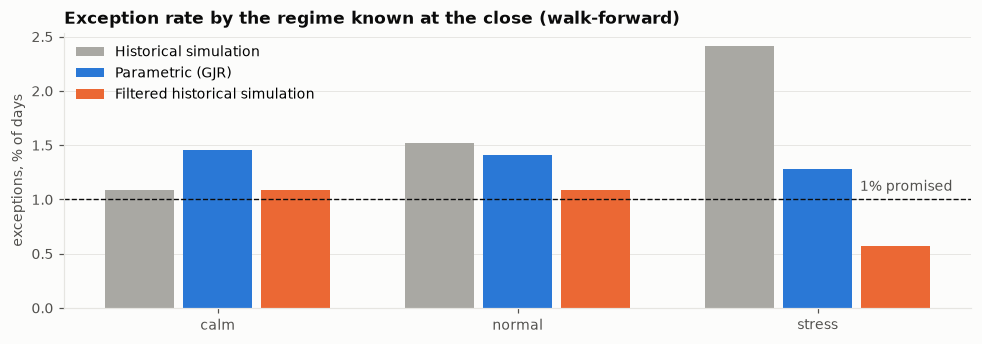

In [8]:
rows = by_regime[(by_regime["fit"] == "walk_forward") & by_regime["method_id"].isin(METHOD_COLORS)]
rates = rows.assign(rate=rows["n_exceptions"] / rows["n_days"] * 100).pivot(
    index="regime_id", columns="method_id", values="rate"
)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.set_axisbelow(True)
width = 0.26
for offset, method in enumerate(METHOD_COLORS):
    positions = np.arange(3) + (offset - 1) * width
    ax.bar(
        positions, rates[method], width=width - 0.03, color=METHOD_COLORS[method], label=METHOD_NAMES[method]
    )
ax.axhline(1.0, color=INK, linewidth=0.9, linestyle="--")
ax.text(2.45, 1.05, "1% promised", color=INK2, ha="right", va="bottom")
ax.set_xticks(range(3), [REGIME_NAMES[r] for r in range(3)])
ax.set_ylabel("exceptions, % of days")
ax.set_title("Exception rate by the regime known at the close (walk-forward)")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Historical simulation is exceeded at roughly the promised rate in calm markets (24 exceptions for 22.0 expected) but 17 times for 7.0 expected in stress (2.4% of days, Kupiec p = 0.001): it uses the last 250 days with equal weights, so when markets turn, its VaR still reflects the calm year behind it. Filtered historical simulation stays near 1% in every regime (Kupiec p ≥ 0.21), because it rescales past returns to current volatility. The parametric GJR method fails the other way: 32 exceptions for 22.0 expected in calm regimes (p = 0.045) and close to 1% in stress. With low volatility, a normal distribution leaves no room for a sudden shock out of a quiet market. The full-history regimes give the same pattern (historical simulation: 21 exceptions for 8.5 in stress; GJR: 30 for 18.5 in calm).

## 4. Volatility forecast errors by regime

Mean QLIKE (Patton, 2011) of each model of [`02_volatility`](02_volatility.ipynb) on the 5-day volatility of the book, by the regime on the forecast date.

In [9]:
book = losses[(losses["fit"] == "walk_forward") & (losses["series_id"] == "book")]
table = book.pivot(index="model_id", columns="regime_id", values="qlike").rename(columns=REGIME_NAMES)
counts = book.drop_duplicates("regime_id").set_index("regime_id")["n_days"].rename(index=REGIME_NAMES)
print("Mean QLIKE of the book's forecasts by walk-forward regime (lower is better); days:", counts.to_dict())
display(table.sort_values("stress").round(3))
best = losses[losses["fit"] == "walk_forward"].loc[
    lambda d: d.groupby(["series_id", "regime_id"])["qlike"].idxmin()
]
print("Lowest QLIKE by series and regime")
best.pivot(index="series_id", columns="regime_id", values="model_id").rename(columns=REGIME_NAMES)

Mean QLIKE of the book's forecasts by walk-forward regime (lower is better); days: {'calm': 1000, 'normal': 619, 'stress': 650}


regime_id,calm,normal,stress
model_id,,,
gjr,0.370,0.392,0.448
gru,0.369,0.393,0.463
har,0.391,0.425,0.483
garch,0.372,0.414,0.490
xgboost,0.377,0.457,0.519
ewma,0.420,0.426,0.528


Lowest QLIKE by series and regime


regime_id,calm,normal,stress
series_id,,,
CAC40,xgboost,gru,gjr
EUR_ZC10Y,garch,ewma,gjr
GOLD,gjr,gjr,har_range
SPX,xgboost,gru,gjr
SX5E,har_range,gru,xgboost
USD_CASH,gjr,gjr,har
book,gru,gjr,gjr


Every model's error rises from calm to stress, and the ranking changes with it: on the book, GJR-GARCH has the lowest QLIKE in normal (0.392) and stress regimes (0.448), and is tied with the GRU in calm ones (0.370 against 0.369). XGBoost loses the most ground in stress (0.377 in calm, 0.519 in stress), behind HAR. Across the seven series, GJR-GARCH has the lowest loss in stress on four (the book, CAC 40, S&P 500 and the bond). The champion chosen in [`02_volatility`](02_volatility.ipynb) holds where it matters for the VaR.

## 5. Conclusions and consequences

| Finding | Consequence |
|---|---|
| The HMM regimes match 2008, March 2020 (from 27 February) and 2022, and last 41 to 69 days on average, against 10 to 17 for a Gaussian mixture | Use the HMM; use the walk-forward fit for anything that must be known at the close |
| Historical simulation: 17 exceptions for 7.0 expected in stress (p = 0.001), close to 1% in calm markets | Its failures come when risk rises, which confirms its rejection in [`04_backtest`](04_backtest.ipynb) |
| Filtered historical simulation stays near 1% in every regime | Confirms the recommended VaR |
| Parametric GJR: 32 exceptions for 22.0 expected in calm regimes (p = 0.045) | Normal tails miss shocks out of quiet markets; the empirical tails of FHS correct it |
| GJR-GARCH has the lowest QLIKE on the book in normal and stress regimes | The volatility champion holds in stress; XGBoost's gains are in calm markets |
| 2015: 54% stress with hindsight, 2% for the walk-forward fit | Regime labels depend on the history seen; always state the fit |

**Limits.** Three states are imposed rather than selected (BIC keeps falling with more states); the features describe equity markets only, not rates or credit; emissions are Gaussian; the walk-forward model is refitted once a year. The regimes are used to analyse the models, not as their inputs. Statistical jump models (Aydınhan et al., 2024; Shu, Yu and Mulvey, 2024), which penalise regime switches directly, are a recent alternative with more stable online labels.

## References

- Ang, A., & Timmermann, A. (2012). Regime changes and financial markets. *Annual Review of Financial Economics*, 4, 313–337.
- Aydınhan, A. O., Kolm, P. N., Mulvey, J. M., & Shu, Y. (2024). Identifying patterns in financial markets: Extending the statistical jump model for regime identification. *Annals of Operations Research*. https://doi.org/10.1007/s10479-024-06035-z
- Hamilton, J. D. (1989). A new approach to the economic analysis of nonstationary time series and the business cycle. *Econometrica*, 57(2), 357–384.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
- Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246–256.
- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257–286.
- Schwarz, G. (1978). Estimating the dimension of a model. *Annals of Statistics*, 6(2), 461–464.
- Shu, Y., Yu, C., & Mulvey, J. M. (2024). Downside risk reduction using regime-switching signals: A statistical jump model approach. *Journal of Asset Management*. https://doi.org/10.1057/s41260-024-00376-x